In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.feature import peak_local_max
from scipy import ndimage

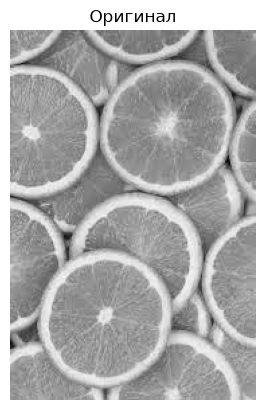

In [2]:
image = cv2.imread('oranges_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал')
plt.axis('off')
plt.show()

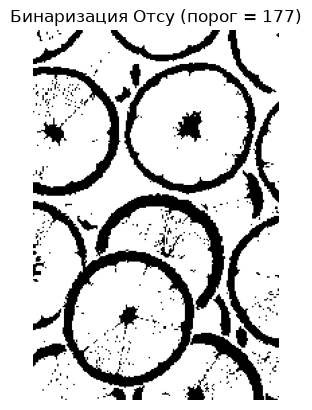

In [3]:
ret, thresh = cv2.threshold(image_gray, 0, 255,
                             cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.imshow(thresh, cmap='gray')
plt.title(f'Бинаризация Отсу (порог = {ret:.0f})')
plt.axis('off')
plt.show()

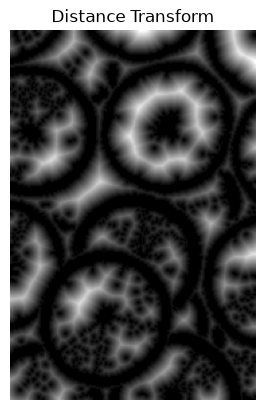

In [4]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

plt.imshow(dist, cmap='gray')
plt.title('Distance Transform')
plt.axis('off')
plt.show()

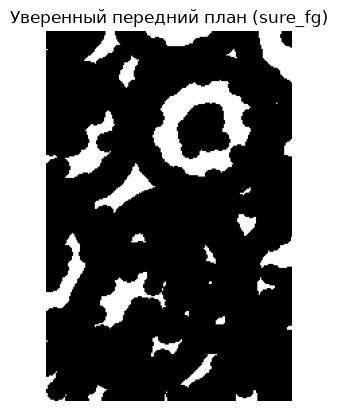

In [5]:
ret, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

plt.imshow(sure_fg, cmap='gray')
plt.title('Уверенный передний план (sure_fg)')
plt.axis('off')
plt.show()

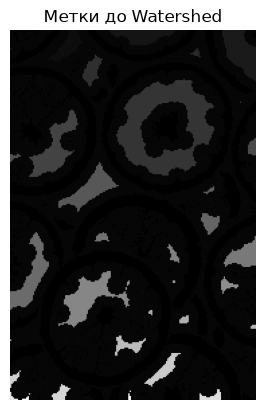

In [6]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[thresh == 0] = 0

plt.imshow(markers, cmap='gray')
plt.title('Метки до Watershed')
plt.axis('off')
plt.show()

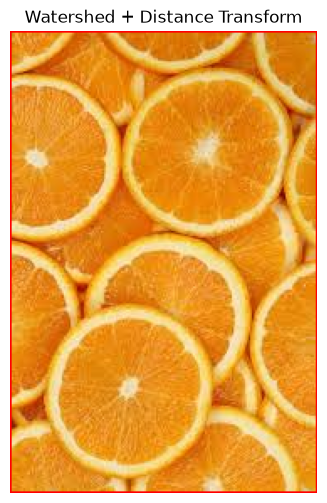

=== Watershed ===
Найдено объектов (апельсинов): 35


In [8]:
markers = cv2.watershed(image, markers)
image_result = image.copy()
image_result[markers == -1] = [0, 0, 255]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image_result, cv2.COLOR_BGR2RGB))
plt.title('Watershed + Distance Transform')
plt.axis('off')
plt.show()

# Подсчёт объектов (исключаем фон и границы)
n_objects = len(np.unique(markers)) - 2
print(f"=== Watershed ===")
print(f"Найдено объектов (апельсинов): {n_objects}")

In [10]:
import math

def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True
    return False

In [11]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

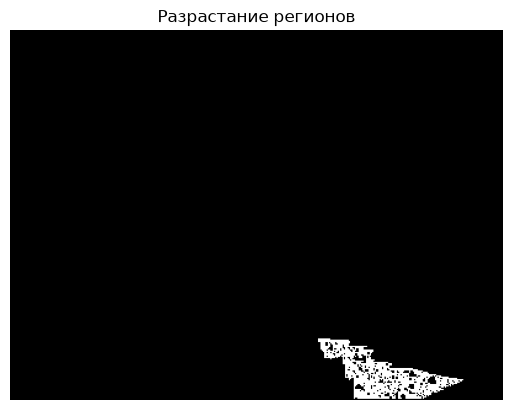

=== Разрастание регионов ===
Seed point: (250, 250)
Пикселей в регионе: 2056


In [13]:
image_rg = cv2.imread('sar_1.jpg')
image_gray_rg = cv2.cvtColor(image_rg, cv2.COLOR_BGR2GRAY)

seed_point = (250, 250)
mask = region_growing(image_gray_rg, seed_point, homo_average, 1, 10)

plt.imshow(mask, cmap='gray')
plt.title('Разрастание регионов')
plt.axis('off')
plt.show()

print(f"=== Разрастание регионов ===")
print(f"Seed point: {seed_point}")
print(f"Пикселей в регионе: {int((mask == 255).sum())}")

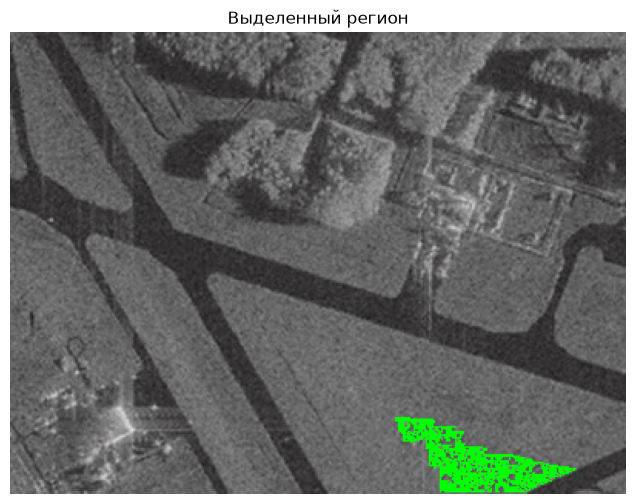

In [14]:
result_rg = image_rg.copy()
result_rg[mask == 255] = [0, 255, 0]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(result_rg, cv2.COLOR_BGR2RGB))
plt.title('Выделенный регион')
plt.axis('off')
plt.show()

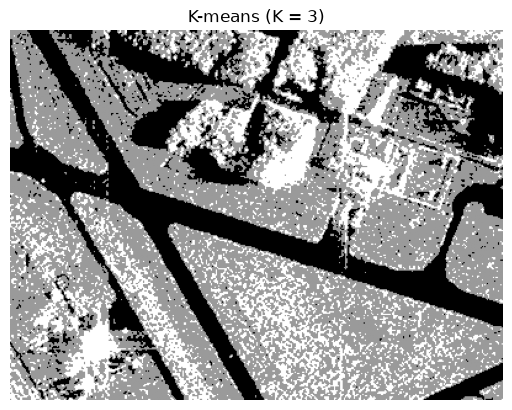

=== K-means ===
Число кластеров: 3
Центры кластеров: [ 96  58 121]


In [15]:
image_km = cv2.imread('sar_1.jpg')
image_gray_km = cv2.cvtColor(image_km, cv2.COLOR_BGR2GRAY)

# Преобразуем в массив (N, 1)
z = image_gray_km.reshape((-1, 1))
z = np.float32(z)

# Критерий остановки и число кластеров
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3

ret, label, center = cv2.kmeans(z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Восстанавливаем изображение
center = np.uint8(center)
res = center[label.flatten()]
res2 = res.reshape(image_gray_km.shape)

plt.imshow(res2, cmap='gray')
plt.title(f'K-means (K = {K})')
plt.axis('off')
plt.show()

print(f"=== K-means ===")
print(f"Число кластеров: {K}")
print(f"Центры кластеров: {center.flatten()}")

In [16]:
def homo_std(img, mask, point, T):
    # Критерий по стандартному отклонению (отличается от среднего)
    values = img[mask > 0]
    if values.size == 0:
        return False
    if np.std(values) <= T:
        return True
    return False

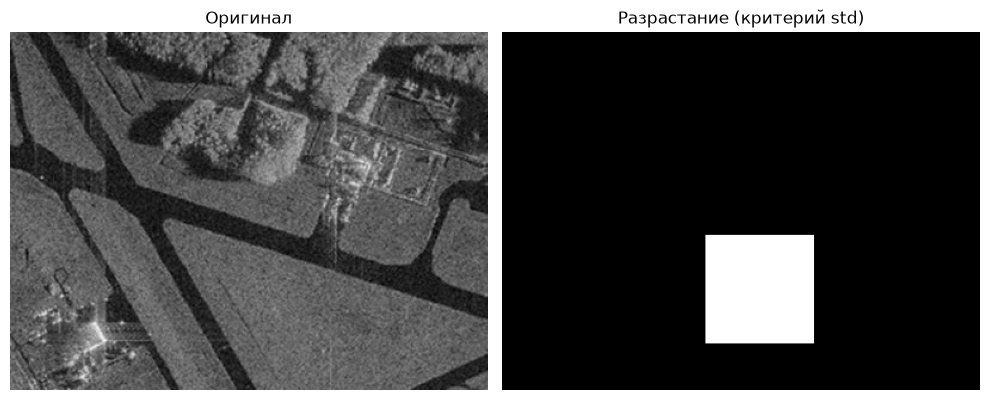

=== Разрастание с критерием std ===
Пикселей в регионе: 8281


In [17]:
image_t4 = cv2.imread('sar_1.jpg')
image_gray_t4 = cv2.cvtColor(image_t4, cv2.COLOR_BGR2GRAY)

# Подбираем seed и параметры
seed = (200, 200)
mask_std = region_growing(image_gray_t4, seed, homo_std, r=2, T=20)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_gray_t4, cmap='gray')
plt.title('Оригинал')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_std, cmap='gray')
plt.title('Разрастание (критерий std)')
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"=== Разрастание с критерием std ===")
print(f"Пикселей в регионе: {int((mask_std == 255).sum())}")

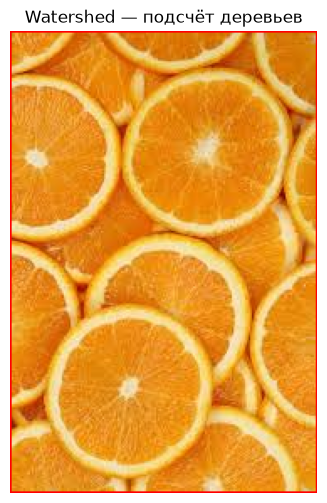

=== Watershed (подсчёт деревьев) ===
Найдено объектов: 28


In [18]:
image_trees = cv2.imread('oranges_1.jpg')
gray_trees = cv2.cvtColor(image_trees, cv2.COLOR_BGR2GRAY)

# Бинаризация
ret, th = cv2.threshold(gray_trees, 0, 255,
                        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Убираем шум
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Distance transform → sure_fg
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist, 0.5 * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Метки
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[th == 0] = 0

# Watershed
markers = cv2.watershed(image_trees, markers)
image_trees[markers == -1] = [0, 0, 255]

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image_trees, cv2.COLOR_BGR2RGB))
plt.title('Watershed — подсчёт деревьев')
plt.axis('off')
plt.show()

n_trees = len(np.unique(markers)) - 2
print(f"=== Watershed (подсчёт деревьев) ===")
print(f"Найдено объектов: {n_trees}")